# Which sensor gives more reliable VRU trajectories: NewSense or Ouster?

**Purpose.** At intersection K305 the team studies pedestrians and cyclists (VRUs). So far we have used the
NewSense object list. It gives one physical object several track IDs and has flickering detections. An Ouster
LiDAR object list exists for part of the morning of 29.10. This notebook compares the two sensors on the same
time and place and builds a scorecard from the numbers. The recommendation at the end is generated from those
numbers, so it reflects whichever run produced it.

**Data used.**
- NewSense object lists, 5-minute JSON files at 10 Hz, 29.10 07:20–11:25 CET, the same clock hours on 28.10, and
  02:00–02:30 CET on 29.10 for the night check.
- Ouster object lists, gzipped JSON lines at 10 Hz, 29.10 07:20–11:25 CET. The file `..._06-20-00` is skipped
  because it starts with stale frames.

**Key facts a reader needs.**
- **Time.** Ouster file names give the *end* of their window in UTC. Data is always selected by timestamp, never
  by file name. The Ouster clock runs about 0.08 s ahead of NewSense.
- **Recalibration.** The Ouster was recalibrated at about 08:13 CET.
  - **Epoch A** is 07:20–08:13 CET (secondary).
  - **Epoch B** is 08:15–11:25 CET (primary).
  - 08:13–08:15 CET is dropped from both sensors.
- **Coordinates.** All positions are shown in the epoch-B Ouster frame, called the *common frame*:
  - NewSense is moved into it with a fitted 2D rigid transform.
  - Epoch-A Ouster data uses that transform composed with the inverse of the epoch-A transform.
- **Variants.**
  - *filtered* (primary): NewSense detections with score ≥ 0.25, and Ouster tracks with a known class.
  - *raw*: all detections.
- **No ground truth.** Neither sensor is ground truth. An unmatched detection is either a false detection by one
  sensor or a miss by the other.

**Run mode.** `sample` mode (the default) uses 10 minutes per epoch. That is enough to test the code but not
to choose a sensor, so all sample results are **provisional**. Set `SENSOR_COMPARE_MODE=full` to run on all data.

## 1. Setup and run mode

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import sensor_compare as sc

RUN_MODE = os.environ.get("SENSOR_COMPARE_MODE", "sample")   # "sample" or "full"
cfg = sc.mode_config(RUN_MODE)
TAG = "(PROVISIONAL, sample)" if RUN_MODE == "sample" else "(full run)"
sc.plot_style()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)
T_START = time.time()
print("run mode:", RUN_MODE, "| epochs:", {k: [str(sc.to_cet(v)) for v in r] for k, r in cfg["epochs"].items()})
if RUN_MODE == "sample":
    display(Markdown("**PROVISIONAL: sample mode, 10 minutes per epoch. Numbers below test the code; they do not decide between the sensors.**"))

run mode: full | epochs: {'A': ['2026-10-29 07:20:00', '2026-10-29 08:13:00'], 'B': ['2026-10-29 08:15:00', '2026-10-29 11:25:00']}


Full mode loads 49 NewSense files for 29.10, 47 Ouster files, 6 night files and 49 NewSense files for 28.10.
This check only lists those files and confirms they exist. It does not open them.

In [2]:
display(sc.check_full_mode_files())
FILES = sc.files_for_mode(RUN_MODE)
print({k: len(v) for k, v in FILES.items()})

,set,n_files,expected,all_exist,first,last
0,ouster,47,47,True,object_list+occupations.log.2026-10-29_06-25-0...,object_list+occupations.log.2026-10-29_10-25-0...
1,newsense_29,49,49,True,k305_object_list_2026-10-29_07-20_to_07-24.json,k305_object_list_2026-10-29_11-20_to_11-24.json
2,newsense_night,6,6,True,k305_object_list_2026-10-29_02-00_to_02-04.json,k305_object_list_2026-10-29_02-25_to_02-29.json
3,newsense_28,49,49,True,k305_object_list_2026-10-28_07-20_to_07-24.json,k305_object_list_2026-10-28_11-20_to_11-24.json


{'ouster': 47, 'newsense_29': 49, 'newsense_night': 6, 'newsense_28': 49}


## 2. Loading, alignment validation and the common region

Each source file is flattened once into Parquet in native coordinates (`output/cache/`). Transforms are applied
in memory after loading. Missing caches are built here, with one progress line per file.

In [3]:
t0 = time.time()
all_files = sorted({p for v in FILES.values() for p in v})
build_info = sc.build_cache(all_files, max_workers=6)
T_CACHE = time.time() - t0
print(f"cache build: {T_CACHE:.0f} s, cache size {sc.cache_size_mb():.0f} MB")

cache: 11 of 151 files already cached, 140 to parse


cache: 11 of 151 files already cached, 140 to parse


  [1/140] object_list+occupations.log.2026-10-29_06-25-00.det.parquet: 2995 frames, 84294 detections, 4 duplicate ts, 1.9 s (elapsed 3 s)


  [1/140] object_list+occupations.log.2026-10-29_06-25-00.det.parquet: 2995 frames, 84294 detections, 4 duplicate ts, 1.9 s (elapsed 3 s)


  [2/140] object_list+occupations.log.2026-10-29_06-55-00.det.parquet: 2567 frames, 89108 detections, 40 duplicate ts, 2.1 s (elapsed 3 s)


  [2/140] object_list+occupations.log.2026-10-29_06-55-00.det.parquet: 2567 frames, 89108 detections, 40 duplicate ts, 2.1 s (elapsed 3 s)


... (207 outputs left out)

  [137/140] k305_object_list_2026-10-29_11-05_to_11-09.det.parquet: 3000 frames, 47475 detections, 0 duplicate ts, 0.8 s (elapsed 30 s)
  [138/140] k305_object_list_2026-10-29_11-10_to_11-14.det.parquet: 3000 frames, 48516 detections, 0 duplicate ts, 0.7 s (elapsed 30 s)
  [139/140] k305_object_list_2026-10-29_11-15_to_11-19.det.parquet: 2999 frames, 53486 detections, 0 duplicate ts, 0.7 s (elapsed 30 s)


  [140/140] k305_object_list_2026-10-29_11-20_to_11-24.det.parquet: 3000 frames, 61360 detections, 0 duplicate ts, 0.7 s (elapsed 31 s)


cache build: 31 s, cache size 292 MB


  [140/140] k305_object_list_2026-10-29_11-20_to_11-24.det.parquet: 3000 frames, 61360 detections, 0 duplicate ts, 0.7 s (elapsed 31 s)


In [4]:
t0 = time.time()
RAW = {"newsense": sc.load_sensor("newsense", FILES["newsense_29"], cfg["epochs"], day="29"),
       "ouster": sc.load_sensor("ouster", FILES["ouster"], cfg["epochs"], day="29")}
VAR = {(s, v): sc.make_variant(RAW[s], v) for s in sc.SENSORS for v in ["filtered", "raw"]}
for (s, v), sd in VAR.items():
    print(f"{s:9s} {v:8s} detections {len(sd.det):>9,d}  tracks {sd.det.trk.nunique():>7,d}  frames {len(sd.frames):>7,d}")
print("track IDs reused after >", sc.TRACK_SPLIT_GAP, "s silence (split into separate tracks):",
      {s: RAW[s].n_id_reuse_splits for s in sc.SENSORS})
print(f"load: {time.time() - t0:.0f} s, peak RSS {sc.rss_mb():.0f} MB")

newsense  filtered detections 1,982,166  tracks  16,005  frames 145,797
newsense  raw      detections 2,833,235  tracks  21,913  frames 145,797
ouster    filtered detections 3,611,431  tracks  26,136  frames 143,240
ouster    raw      detections 3,773,171  tracks  39,859  frames 143,240
track IDs reused after > 30.0 s silence (split into separate tracks): {'newsense': 1170, 'ouster': 0}
load: 8 s, peak RSS 3017 MB


### Validation gates
The gates run before any metric and stop the notebook if they fail.

**Gate 1: alignment.** For each 5-minute window this is the share of NewSense vehicles faster than 4 m/s that
have an Ouster vehicle within 1 m in the time-paired frame. Only paired frames count. Values around 0.8–0.9 mean
the transforms and clocks line up.
- The gate fails if the median over windows is below 0.70, or if any epoch-B window is below 0.50.
- The figure also documents the recalibration: each epoch is aligned with its own transform.

,epoch,window,share,n,window_cet
0,A,1793254800,0.896,9490,2026-10-29 07:20:00
1,A,1793255100,0.867,9123,2026-10-29 07:25:00
2,A,1793255400,0.876,8763,2026-10-29 07:30:00
3,A,1793255700,0.864,10929,2026-10-29 07:35:00
4,A,1793256000,0.893,10513,2026-10-29 07:40:00
5,A,1793256300,0.888,11907,2026-10-29 07:45:00
6,A,1793256600,0.865,9893,2026-10-29 07:50:00
7,A,1793256900,0.891,10460,2026-10-29 07:55:00
8,A,1793257200,0.873,10035,2026-10-29 08:00:00
9,A,1793257500,0.848,8224,2026-10-29 08:05:00


{'gate': 'alignment', 'median_share': 0.87, 'min_epochB_window': 0.835, 'passed': True}


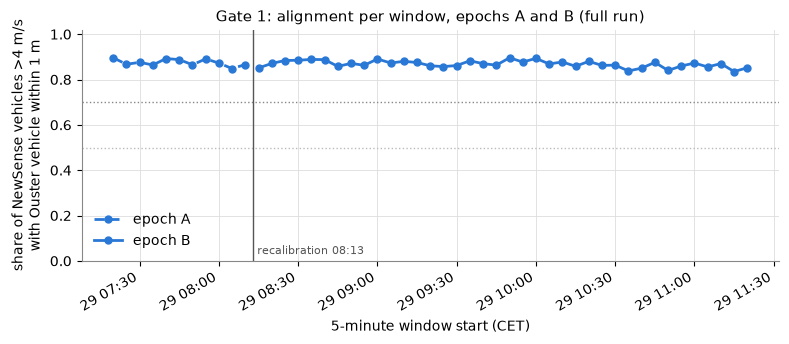

In [5]:
ALIGN = sc.alignment_share(VAR[("newsense", "filtered")], RAW["ouster"])
sc.save_table(ALIGN, cfg, "gate1_alignment_per_window")
display(ALIGN)
GATE1 = sc.gate_alignment(ALIGN)
print(GATE1)
fig = sc.plot_alignment(ALIGN, TAG); sc.save_fig(fig, cfg, "gate1_alignment"); plt.show()

**Gate 2: clock offset.** The same share is computed for clock offsets from −0.30 to +0.30 s, on up to three
epoch-B windows spread over the epoch. The best offset must lie between 0 and +0.15 s. After that, +0.08 s is
used everywhere.

At 10 Hz neighbouring offsets often select the same frame, so the curve has steps.

window_cet,2026-10-29 08:15:00,2026-10-29 09:45:00,2026-10-29 11:20:00
offset,,,
-0.30,0.013,0.004,0.012
-0.25,0.013,0.012,0.012
-0.20,0.064,0.012,0.052
-0.15,0.064,0.116,0.052
-0.10,0.399,0.116,0.256
-0.05,0.399,0.643,0.256
0.00,0.877,0.643,0.860
0.05,0.877,0.863,0.860
0.10,0.850,0.863,0.852


{'gate': 'clock_offset', 'best_offset_s': 0.05, 'share_at_best': 0.867, 'passed': True}


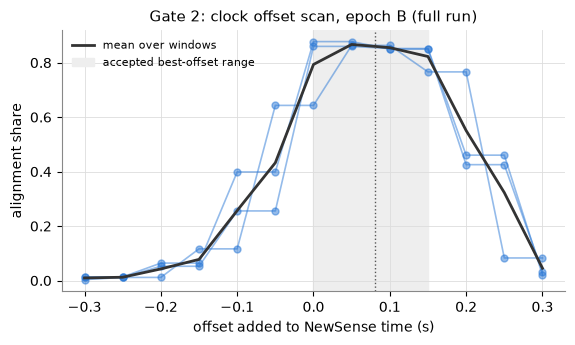

In [6]:
b_windows = np.sort(np.unique(sc._window_of(VAR[("newsense", "filtered")].det.query("epoch == 'B'").ts)))
scan_windows = np.unique(b_windows[np.round(np.linspace(0, len(b_windows) - 1, 3)).astype(int)])
SCAN = sc.clock_offset_scan(VAR[("newsense", "filtered")], RAW["ouster"], scan_windows)
sc.save_table(SCAN, cfg, "gate2_clock_offset_scan")
display(SCAN.pivot_table(index="offset", columns="window_cet", values="share"))
GATE2 = sc.gate_clock(SCAN)
print(GATE2)
fig = sc.plot_clock(SCAN, TAG); sc.save_fig(fig, cfg, "gate2_clock_offset"); plt.show()

**Gate 3: coverage.** After filtering, each sensor must have detections in every 5-minute window of both
epochs. A shorter last window, such as epoch A ending at 08:13 in full mode, still has to contain data.

In [7]:
COVER = sc.gate_coverage({s: VAR[(s, "filtered")] for s in sc.SENSORS}, cfg["epochs"])
sc.save_table(COVER, cfg, "gate3_coverage")
display(COVER)
print("Gate 3 (coverage): passed")

,epoch,window,duration,n_det_newsense,n_det_ouster,window_cet
0,A,1793254800,300,39257,78128,2026-10-29 07:20:00
1,A,1793255100,300,55608,111344,2026-10-29 07:25:00
2,A,1793255400,300,68597,141854,2026-10-29 07:30:00
3,A,1793255700,300,73602,131675,2026-10-29 07:35:00
4,A,1793256000,300,68134,134133,2026-10-29 07:40:00
5,A,1793256300,300,69725,103224,2026-10-29 07:45:00
6,A,1793256600,300,46662,85002,2026-10-29 07:50:00
7,A,1793256900,300,51208,88573,2026-10-29 07:55:00
8,A,1793257200,300,40731,80100,2026-10-29 08:00:00
9,A,1793257500,300,32067,60486,2026-10-29 08:05:00


Gate 3 (coverage): passed


### Common region
The Ouster sees about ±80 m and NewSense about ±40 m, so every comparison is restricted to the area both see.
- **Region cells.** A 2 m cell belongs to the region if each sensor has enough moving detections there (speed
  ≥ 1 m/s) in epoch B. The threshold is set by the run mode.
- **Which data is used.** Detection-level metrics use detections inside the region. Track-level metrics use
  tracks with at least half of their detections inside it.
- **Reuse.** The same region is used for epoch A, the night check and 28.10.

,region_cells,sensor,variant,epoch,det_share_in_region,tracks_in_region
0,598,newsense,filtered,A,0.829,4309
1,598,newsense,filtered,B,0.747,10298
2,598,newsense,raw,A,0.718,5395
3,598,newsense,raw,B,0.635,13340
4,598,ouster,filtered,A,0.502,2707
5,598,ouster,filtered,B,0.457,5465
6,598,ouster,raw,A,0.502,4430
7,598,ouster,raw,B,0.451,7689


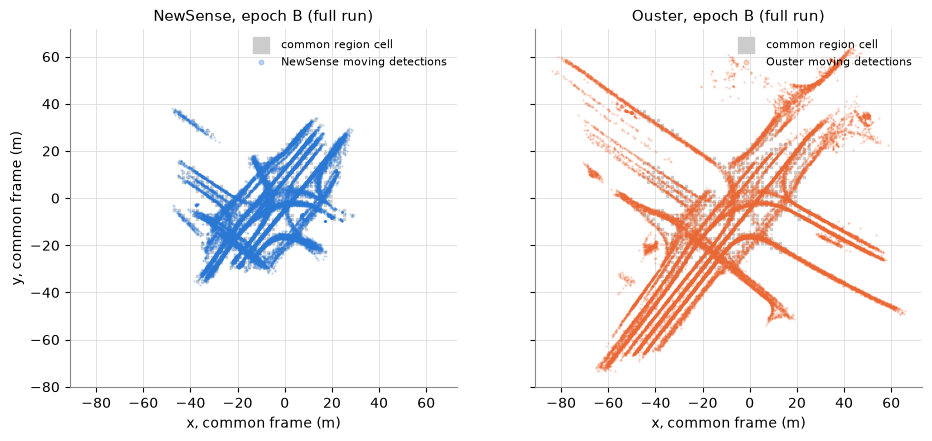

In [8]:
REGION = sc.build_region(VAR[("newsense", "filtered")], VAR[("ouster", "filtered")], "B", cfg["region_min"])
VAR = {k: sc.add_region(sd, REGION) for k, sd in VAR.items()}
REG_TAB = pd.DataFrame([dict(sensor=s, variant=v, epoch=ep,
                             det_share_in_region=float(sd.det.loc[sd.det.epoch == ep, "in_region"].mean()),
                             tracks_in_region=int(sd.det.loc[(sd.det.epoch == ep) & sd.det.trk_in_region, "trk"].nunique()))
                        for (s, v), sd in VAR.items() for ep in sorted(cfg["epochs"])])
REG_TAB.insert(0, "region_cells", len(REGION.keys))
sc.save_table(REG_TAB, cfg, "common_region")
display(REG_TAB)
fig = sc.plot_region(REGION, VAR[("newsense", "filtered")], VAR[("ouster", "filtered")], "B", TAG)
sc.save_fig(fig, cfg, "common_region_map"); plt.show()

## 3. Stream health
Stream health is measured on the stream of emitted frames, before any track logic, and does not depend on the
variant.
- **Measures.** Frames per 5 minutes (3000 expected at 10 Hz, scaled for shorter windows), the share of frame
  gaps above 0.15 s, duplicate timestamps (the second frame is dropped), and the longest gap.
- **Reading the figure.** A ratio of 1.0 is a complete stream. Dips mean dropped frames, which also lower the
  number of frames that can be paired across sensors.

,sensor,day,epoch,n_frames,frames_per_5min,min_window_frame_ratio,gap_share_gt_0p15s,gaps_ge_0p2s,duplicate_ts,longest_gap_s
0,newsense,29,A,31799,2999.909,1.000,3.145e-05,1,0,0.2
1,newsense,29,B,113998,2999.947,1.000,2.632e-05,1,0,0.2
2,ouster,29,A,29499,2790.394,0.848,7.485e-02,750,318,7.5
3,ouster,29,B,113741,2993.184,0.966,1.090e-03,52,83,7.5


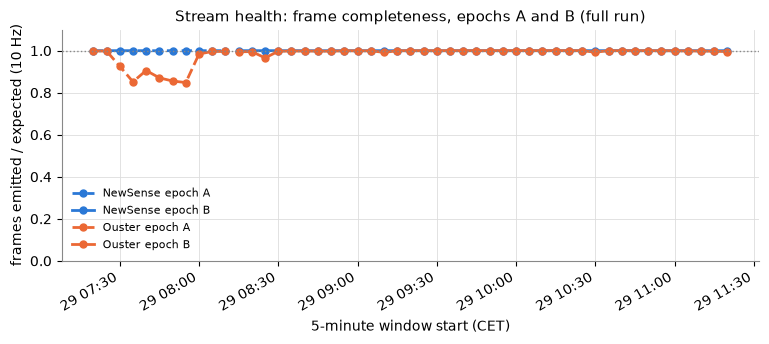

In [9]:
HEALTH = pd.concat([sc.stream_health(RAW[s]) for s in sc.SENSORS], ignore_index=True)
HEALTH_W = pd.concat([sc.stream_health_windows(RAW[s]) for s in sc.SENSORS], ignore_index=True)
sc.save_table(HEALTH, cfg, "stream_health"); sc.save_table(HEALTH_W, cfg, "stream_health_per_window")
display(HEALTH)
fig = sc.plot_stream(HEALTH_W, TAG); sc.save_fig(fig, cfg, "stream_health"); plt.show()

## 4. Single-sensor track quality
Each sensor is judged on its own: per group, per epoch and per variant, on tracks in the common region. Lower
is better for every panel.

| Metric | What it measures |
| :--- | :--- |
| Flickering | Share of tracks shorter than 1 s |
| Gaps inside tracks | Missing frames between a track's first and last detection, counted in the sensor's own emitted frames |
| Class stability | Tracks that switch between known classes |
| Implausible motion | Frame steps faster than 4 / 15 / 30 m/s for ped / bike / veh |
| Jitter | RMS of the second difference of position, on tracks that move at least 3 m |
| ID handovers | A track ends and, within 2 s, a new track of the same group starts within 1.5 m of the extrapolated position |

- **Handovers** count ID switches that each sensor causes by itself.
- **Shares near zero are good.** A handover rate of tens per 100 tracks means a VRU trajectory is regularly
  split into several IDs.
- **Built-in advantage.** NewSense reports one class and one score per track and does not report gaps inside a
  track: it starts a new ID instead. So the gap and class-stability rows can favour NewSense by design rather
  than by quality. The conclusion therefore checks the decision both with and without those rows.

single-sensor metrics: 29 s


epoch                            B                                                                   A                                                \
group                          ped                   bike                   veh                    ped                   bike                    veh   
sensor                    newsense      ouster   newsense     ouster   newsense     ouster    newsense      ouster   newsense     ouster    newsense   
n_tracks                  2204.000    1194.000    555.000  3.640e+02  7.539e+03  3.907e+03    1110.000    1021.000  6.180e+02  3.720e+02    2581.000   
n_det                   232119.000  256286.000  51227.000  7.904e+04  7.728e+05  8.535e+05  143193.000  202151.000  6.048e+04  8.481e+04  270257.000   
flicker_track_share          0.059       0.219      0.065  7.418e-02  4.006e-02  1.029e-01       0.068       0.204  8.576e-02  6.452e-02       0.044   
flicker_det_share            0.006       0.005      0.007  1.822e-03  3.977e-03  1.933e-03       0.005       0.005  8.863e-03  1.226e-03       0.004   
gap_track_share              0.000       0.121      0.000  1.978e-01  2.653e-04  1.190e-01       0.000       0.109  1.618e-03  2.661e-01       0.000   
gap_mean_missing_share       0.000       0.012      0.000  1.812e-02  6.478e-05  1.197e-02       0.000       0.011  6.056e-04  2.577e-02       0.000   
class_multi_share            0.000       0.039      0.000  2.115e-01  0.000e+00  0.000e+00       0.000       0.102  3.236e-03  3.011e-01       0.000   
unk_det_share                0.000       0.043      0.000  5.380e-02  0.000e+00  4.487e-02       0.000       0.075  0.000e+00  4.629e-02       0.000   
implausible_step_share       0.004       0.019      0.000  1.908e-04  0.000e+00  3.616e-04       0.003       0.040  3.341e-05  8.421e-04       0.000   
step_speed_p99               2.895       5.221      6.729  1.028e+01  1.200e+01  1.415e+01       2.959       6.901  6.022e+00  8.631e+00      11.322   
n_steps                 229915.000  254902.000  50672.000  7.860e+04  7.652e+05  8.490e+05  142083.000  200990.000  5.986e+04  8.431e+04  267676.000   
jitter_rms_m                 0.063       0.124      0.099  1.303e-01  1.563e-01  2.356e-01       0.064       0.217  3.297e-01  2.146e-01       0.141   
n_jitter                115213.000  233271.000  40034.000  7.536e+04  6.505e+05  8.387e+05   63421.000  167197.000  3.871e+04  7.838e+04  237910.000   
static_long_count          293.000      30.000     21.000  7.000e+00  2.210e+02  5.000e+00     177.000      44.000  4.700e+01  1.100e+01      38.000   
static_long_det_share        0.285       0.024      0.102  1.360e-02  5.814e-02  1.119e-03       0.400       0.058  1.786e-01  2.691e-02       0.032   
handovers_per_100           18.781      31.960      5.967  4.986e+00  2.272e+00  2.592e+00      21.338      25.959  6.149e+00  8.602e+00       2.957   
n_handover_tracks         2199.000    1189.000    553.000  3.610e+02  7.527e+03  3.896e+03    1106.000    1017.000  6.180e+02  3.720e+02    2570.000   

epoch                              
group                              
sensor                     ouster  
n_tracks                1.314e+03  
n_det                   2.821e+05  
flicker_track_share     1.347e-01  
flicker_det_share       2.563e-03  
gap_track_share         1.644e-01  
gap_mean_missing_share  1.691e-02  
class_multi_share       0.000e+00  
unk_det_share           1.439e-02  
implausible_step_share  1.675e-04  
step_speed_p99          1.368e+01  
n_steps                 2.806e+05  
jitter_rms_m            3.683e-01  
n_jitter                2.773e+05  
static_long_count       2.000e+00  
static_long_det_share   1.857e-03  
handovers_per_100       3.979e+00  
n_handover_tracks       1.307e+03

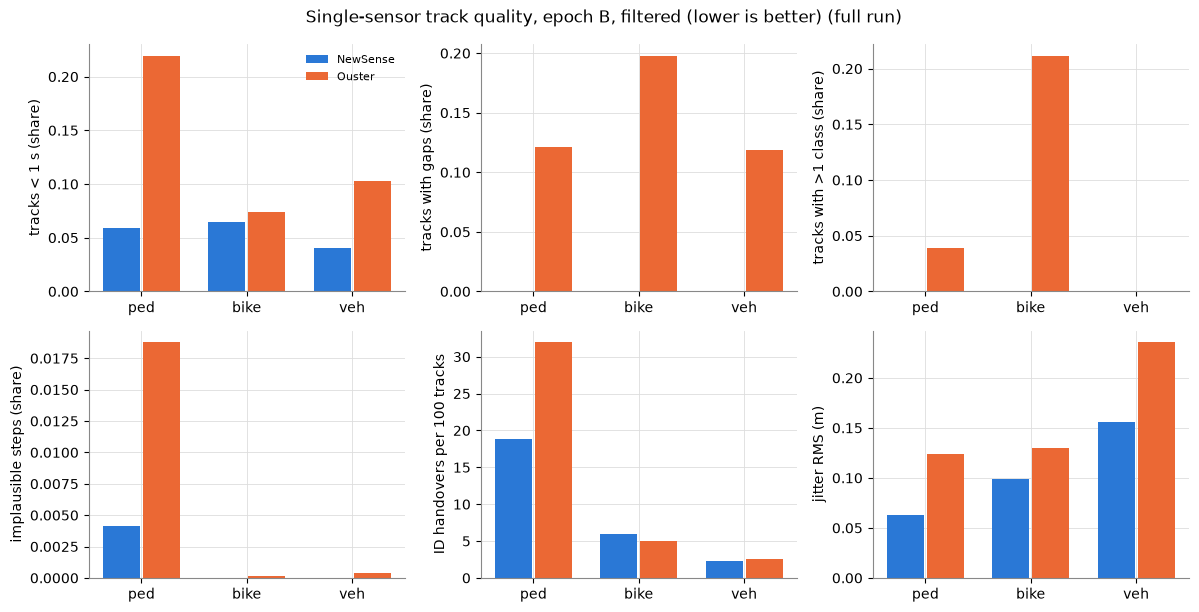

In [10]:
t0 = time.time()
single_rows, TRACKS = [], {}
for (s, v), sd in VAR.items():
    m, tt = sc.single_sensor_metrics(sd, v)
    single_rows.append(m); TRACKS[(s, v)] = tt
SINGLE = pd.concat(single_rows, ignore_index=True)
order = {g: i for i, g in enumerate(sc.GROUPS)}
SINGLE = SINGLE.sort_values(["variant", "epoch", "group", "sensor"], key=lambda c: c.map(order) if c.name == "group" else c,
                            ascending=[True, False, True, True]).reset_index(drop=True)
sc.save_table(SINGLE, cfg, "single_sensor_metrics")
print(f"single-sensor metrics: {time.time() - t0:.0f} s")
display(SINGLE[SINGLE.variant == "filtered"].set_index(["epoch", "group", "sensor"]).drop(columns=["day", "variant"]).T)
fig = sc.plot_single(SINGLE, "B", "filtered", TAG); sc.save_fig(fig, cfg, "single_sensor_epochB"); plt.show()

## 5. Cross-sensor comparison: same time, same place
This is the core of the comparison. It uses the filtered variants, with epoch B as the primary result and epoch A
as the secondary one.
- **Frame pairing.** Each NewSense frame is paired with the Ouster frame nearest to `ts + 0.08 s`, if that frame
  is within 0.06 s.
- **Matching.** In each paired frame, detections are matched one-to-one on centre distance (Hungarian
  assignment, class ignored, at most 2 m). The matched pairs are cached.

In [11]:
t0 = time.time()
NSF, OUF = VAR[("newsense", "filtered")], VAR[("ouster", "filtered")]
MATCHES, PSTATS, PAIR = sc.match_detections(NSF, OUF, RUN_MODE, "filtered")
sc.mark_matched(NSF, OUF, MATCHES, PAIR)
PAIR_TAB = pd.DataFrame([PSTATS]).assign(ns_unpaired_share=lambda d: d.ns_unpaired / d.ns_frames,
                                         median_match_dist_m=float(MATCHES["dist"].median()))
sc.save_table(PAIR_TAB, cfg, "frame_pairing")
display(PAIR_TAB)
print(f"matching: {time.time() - t0:.0f} s, peak RSS {sc.rss_mb():.0f} MB")

,ns_frames,ns_unpaired,ns_unpaired_by_conflict,ou_frames,ou_unpaired,n_pairs,ns_unpaired_share,median_match_dist_m
0,145797,2719,2241,143240,162,1192581,0.019,0.281


matching: 8 s, peak RSS 3791 MB


### 5.1 Confirmation rate
This is the share of a sensor's detections, in paired frames and inside the region, that the other sensor also
reports within 2 m. It is split into moving tracks (net displacement ≥ 3 m) and static tracks.
- **Reading the figure.** Higher is better.
- **Caution.** An unmatched detection is either a false detection by this sensor or a miss by the other. The data
  alone cannot tell which.
- **Static tracks.** Low static rates may be ghosts on fixed structures, or people waiting whom the other sensor
  misses.

sensor              newsense  ouster
epoch group motion                  
B     bike  all        0.774   0.728
            moving     0.816   0.738
            static     0.614   0.500
      ped   all        0.566   0.587
            moving     0.916   0.605
            static     0.226   0.396
      veh   all        0.837   0.730
            moving     0.906   0.732
            static     0.417   0.515
A     bike  all        0.890   0.669
            moving     0.946   0.669
            static     0.790   0.675
      ped   all        0.745   0.629
            moving     0.925   0.629
            static     0.605   0.630
      veh   all        0.890   0.732
            moving     0.908   0.734
            static     0.737   0.392

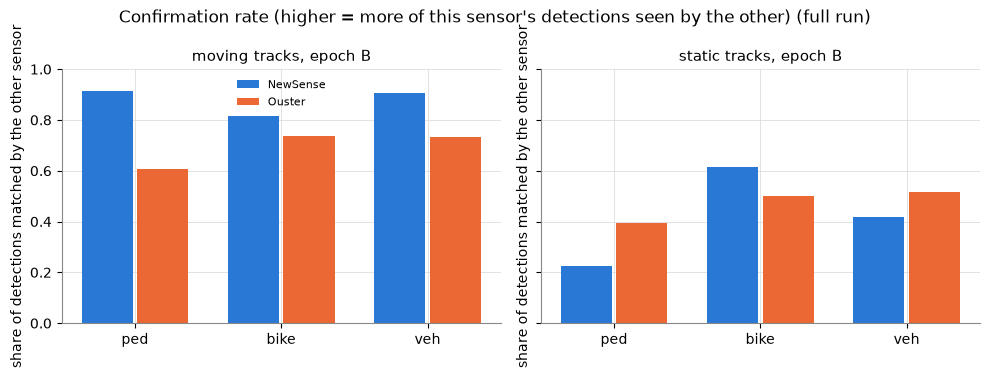

In [12]:
CONF = pd.concat([sc.confirmation_rates(NSF, TRACKS[("newsense", "filtered")]),
                  sc.confirmation_rates(OUF, TRACKS[("ouster", "filtered")])], ignore_index=True)
sc.save_table(CONF, cfg, "confirmation_rates")
display(CONF.pivot_table(index=["epoch", "group", "motion"], columns="sensor", values="confirmation_rate")
        .sort_index(level=[0, 1], ascending=[False, True]))
fig = sc.plot_confirmation(CONF, "B", TAG); sc.save_fig(fig, cfg, "confirmation_epochB"); plt.show()

### 5.2 Class agreement
The confusion matrix of track groups over matched pairs in epoch B. Rows are NewSense groups, columns are Ouster
groups. Mass off the diagonal means the sensors disagree on what the object is.

In [13]:
CONFUSION = {ep: sc.class_confusion(MATCHES, ep) for ep in sorted(cfg["epochs"])}
for ep, cm in CONFUSION.items():
    sc.save_table(cm, cfg, f"class_confusion_epoch{ep}", index=True)
display(CONFUSION["B"])

Ouster group,ped,bike,veh,unk
NewSense group,,,,
ped,121260,8873,25,0
bike,11904,26978,7,0
veh,8481,14091,631069,0
unk,0,0,0,0


### 5.3 ID fragmentation seen by the other sensor
This measures the "several IDs for one object" complaint directly.
- **Method.** For every track of one sensor with at least 30 matched detections, count the distinct IDs of the
  *other* sensor that cover at least 5 of those matched frames.
- **Attribution.** Ouster tracks that map to several NewSense IDs measure **NewSense** fragmentation. NewSense
  tracks that map to several Ouster IDs measure **Ouster** fragmentation. The figure is labelled by the sensor
  whose fragmentation is measured.
- **Reading the figure.** Lower is better. Values near 0 mean one ID per object.

,direction,measures_fragmentation_of,epoch,group,n_tracks,mean_n_ids,share_n_ids_ge2,changes,minutes,id_changes_per_min
0,ou->ns,newsense,A,bike,250,2.916,0.776,1454,95.520,15.222
1,ou->ns,newsense,A,ped,493,3.061,0.751,3608,241.483,14.941
2,ou->ns,newsense,A,veh,1027,1.237,0.145,392,309.534,1.266
3,ou->ns,newsense,B,bike,246,2.390,0.667,1240,83.867,14.785
4,ou->ns,newsense,B,ped,556,2.273,0.595,1544,224.531,6.877
5,ou->ns,newsense,B,veh,3171,1.186,0.113,843,856.027,0.985
6,ns->ou,ouster,A,bike,335,1.934,0.510,1580,86.552,18.255
7,ns->ou,ouster,A,ped,560,1.630,0.362,1761,176.003,10.005
8,ns->ou,ouster,A,veh,1793,1.073,0.044,608,381.198,1.595
9,ns->ou,ouster,B,bike,295,1.397,0.298,383,67.130,5.705


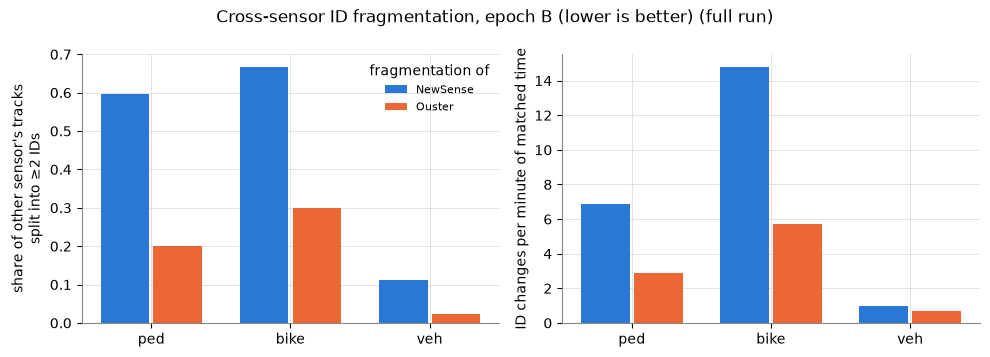

In [14]:
fr1, per1 = sc.fragmentation(MATCHES, "ou->ns", TRACKS[("ouster", "filtered")])
fr2, per2 = sc.fragmentation(MATCHES, "ns->ou", TRACKS[("newsense", "filtered")])
FRAG = pd.concat([fr1, fr2], ignore_index=True)
sc.save_table(FRAG, cfg, "fragmentation")
display(FRAG)
fig = sc.plot_fragmentation(FRAG, "B", TAG); sc.save_fig(fig, cfg, "fragmentation_epochB"); plt.show()

### 5.4 Unconfirmed tracks and video-check candidates
An unconfirmed track has under 10% of its paired-frame detections matched by the other sensor.
- **Map.** Clusters at fixed places suggest ghosts on structures, or blind spots of the other sensor.
- **Video-check list.** The 20 longest unconfirmed VRU tracks per sensor are written to
  `video_check_candidates.csv`, so someone can check them against the Miovision video.

,sensor,epoch,group,n_tracks,n_unconfirmed,unconfirmed_share,unconfirmed_moving,unconfirmed_static,median_duration_s,total_duration_s
0,newsense,A,bike,614,27,0.044,2,25,1.800,152.599
1,newsense,A,ped,1109,196,0.177,0,196,4.100,2576.200
2,newsense,A,veh,2578,198,0.077,22,176,2.100,794.801
3,newsense,B,bike,555,52,0.094,14,38,2.300,472.500
4,newsense,B,ped,2201,1122,0.510,5,1117,3.901,8533.489
5,newsense,B,veh,7536,1073,0.142,85,988,3.000,6698.003
6,ouster,A,bike,372,66,0.177,44,22,10.350,932.506
7,ouster,A,ped,1021,253,0.248,96,157,1.700,2488.104
8,ouster,A,veh,1314,219,0.167,101,118,0.400,2866.058
9,ouster,B,bike,364,77,0.212,55,22,6.600,705.907


video-check candidates per sensor: {'newsense': 20, 'ouster': 20}


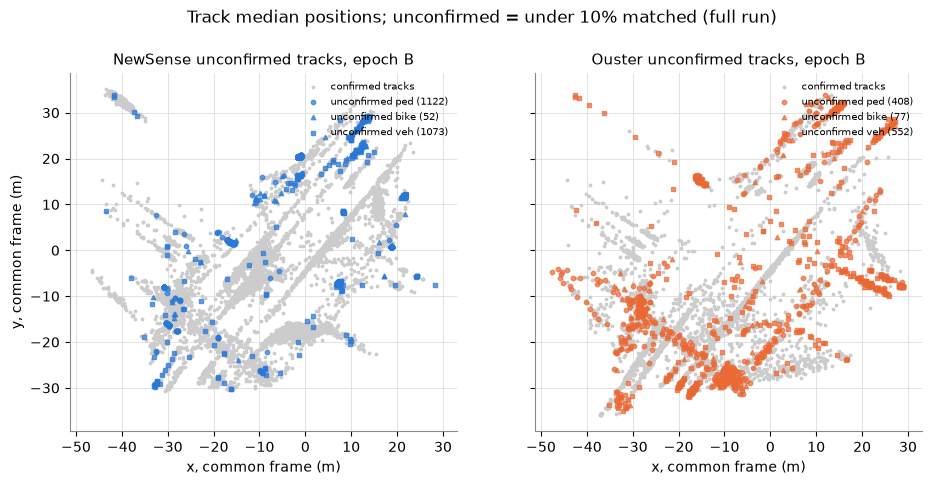

In [15]:
UN = pd.concat([sc.unconfirmed_tracks(NSF, TRACKS[("newsense", "filtered")]),
                sc.unconfirmed_tracks(OUF, TRACKS[("ouster", "filtered")])])
UN_SUM = sc.unconfirmed_summary(UN)
sc.save_table(UN_SUM, cfg, "unconfirmed_tracks")
VIDEO = sc.video_candidates(UN)
sc.save_table(VIDEO, cfg, "video_check_candidates")
display(UN_SUM)
print("video-check candidates per sensor:", VIDEO.groupby("sensor").size().to_dict())
fig = sc.plot_unconfirmed_map(UN, "B", TAG); sc.save_fig(fig, cfg, "unconfirmed_map_epochB"); plt.show()

## 6. Night check for NewSense ghosts
Static VRU tracks that only NewSense sees could be real people waiting whom the Ouster misses. They could also
be false detections on poles and signs.
- **Night data.** At night almost nobody is on the street, so static long VRU tracks there mark fixed-structure
  ghosts. They are mapped on the same 2 m grid.
- **Day comparison.** The table gives the share of daytime unconfirmed static VRU detections that fall into those
  night cells. Confirmed static VRU detections are shown as a baseline.
- **Reading the table.** An unconfirmed share well above the baseline points to ghosts.

,night_static_vru_tracks,night_cells,epoch,detections,n_det,share_in_night_static_cells
0,29,7,A,unconfirmed (unmatched),32790,0.496
1,29,7,A,confirmed (matched),59330,0.022
2,29,7,B,unconfirmed (unmatched),93614,0.155
3,29,7,B,confirmed (matched),32616,0.030


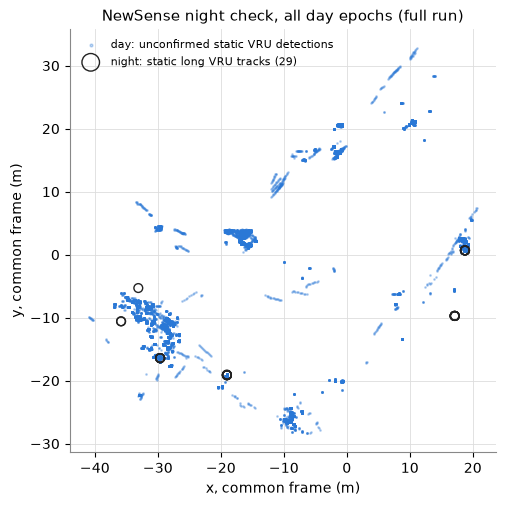

In [16]:
NIGHT = sc.make_variant(sc.load_sensor("newsense", FILES["newsense_night"], cfg["night"], day="29N"), "filtered")
NIGHT_KEYS, NIGHT_ST = sc.night_static_cells(NIGHT)
NIGHT_TAB = sc.night_overlap(NSF, TRACKS[("newsense", "filtered")], NIGHT_KEYS)
NIGHT_TAB.insert(0, "night_static_vru_tracks", len(NIGHT_ST)); NIGHT_TAB.insert(1, "night_cells", len(NIGHT_KEYS))
sc.save_table(NIGHT_TAB, cfg, "night_check")
display(NIGHT_TAB)
fig = sc.plot_night(NIGHT_ST, NSF, TRACKS[("newsense", "filtered")], TAG); sc.save_fig(fig, cfg, "night_check_map"); plt.show()

## 7. VRU counts per 5 minutes
A valid traversal is a `ped` or `bike` track that lasts at least 2 s and moves at least 3 m. It is counted in the
window where it starts.
- **Reading the figures.** The counts should track each other over time, and the per-window points should sit
  near the diagonal.
- **Caution.** A sensor that fragments tracks counts *higher*, so a higher count is not better by itself.

sensor       newsense  ouster
epoch group                  
B     bike        335     310
      ped         647     690
A     bike        292     306
      ped         383     545

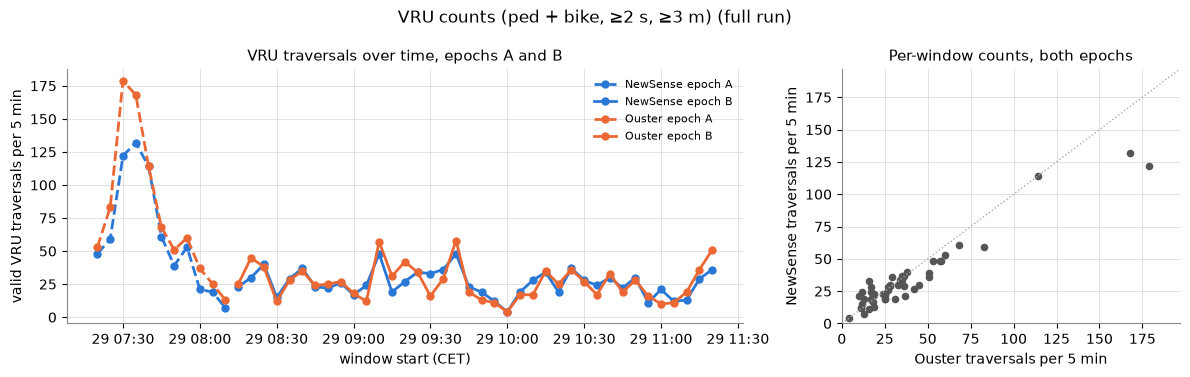

In [17]:
COUNTS = pd.concat([sc.vru_counts(TRACKS[(s, "filtered")], s) for s in sc.SENSORS], ignore_index=True)
sc.save_table(COUNTS, cfg, "vru_counts_per_5min")
display(COUNTS.pivot_table(index=["epoch", "group"], columns="sensor", values="n", aggfunc="sum")
        .sort_index(ascending=[False, True]))
fig = sc.plot_counts(COUNTS, TAG); sc.save_fig(fig, cfg, "vru_counts"); plt.show()

## 8. NewSense on 28.10 versus 29.10
The Ouster has no data on 28.10, so a same-time comparison is not possible on that day. The single-sensor
metrics are computed for NewSense on 28.10 and shown next to the 29.10 NewSense values for the same clock hours.
- **Reading the figure.** Similar bars mean the NewSense behaviour seen on 29.10 is typical. Large differences
  mean one day is unusual.

epoch                           A                                                                    B                                                 \
group                        bike                    ped                    veh                   bike                    ped                     veh   
day                            28         29          28          29         28          29         28         29          28          29          28   
n_tracks                  836.000  6.180e+02    1480.000    1110.000  2.349e+03    2581.000    989.000    555.000    3073.000    2204.000    6539.000   
n_det                   90168.000  6.048e+04  145691.000  143193.000  3.081e+05  270257.000  90842.000  51227.000  294339.000  232119.000  858149.000   
flicker_track_share         0.048  8.576e-02       0.068       0.068  2.043e-02       0.044      0.058      0.065       0.084       0.059       0.019   
flicker_det_share           0.005  8.863e-03       0.007       0.005  1.561e-03       0.004      0.006      0.007       0.009       0.006       0.001   
gap_track_share             0.000  1.618e-03       0.000       0.000  1.277e-03       0.000      0.000      0.000       0.000       0.000       0.000   
gap_mean_missing_share      0.000  6.056e-04       0.000       0.000  2.513e-04       0.000      0.000      0.000       0.000       0.000       0.000   
class_multi_share           0.000  3.236e-03       0.000       0.000  0.000e+00       0.000      0.000      0.000       0.000       0.000       0.000   
unk_det_share               0.000  0.000e+00       0.000       0.000  0.000e+00       0.000      0.000      0.000       0.000       0.000       0.000   
implausible_step_share      0.000  3.341e-05       0.004       0.003  0.000e+00       0.000      0.000      0.000       0.001       0.004       0.000   
step_speed_p99              7.495  6.022e+00       3.228       2.959  1.164e+01      11.322      7.569      6.729       2.480       2.895      12.324   
n_steps                 89332.000  5.986e+04  144211.000  142083.000  3.058e+05  267676.000  89853.000  50672.000  291266.000  229915.000  851610.000   
jitter_rms_m                0.114  3.297e-01       0.069       0.064  1.719e-01       0.141      0.113      0.099       0.065       0.063       0.175   
n_jitter                61213.000  3.871e+04   75711.000   63421.000  2.818e+05  237910.000  64538.000  40034.000  174491.000  115213.000  781564.000   
static_long_count          62.000  4.700e+01     152.000     177.000  4.700e+01      38.000     53.000     21.000     228.000     293.000     125.000   
static_long_det_share       0.175  1.786e-01       0.247       0.400  3.807e-02       0.032      0.121      0.102       0.166       0.285       0.031   
handovers_per_100          10.407  6.149e+00      29.181      21.338  4.835e+00       2.957      8.713      5.967      25.668      18.781       3.540   
n_handover_tracks         836.000  6.180e+02    1477.000    1106.000  2.337e+03    2570.000    987.000    553.000    3070.000    2199.000    6525.000   

epoch                              
group                              
day                            29  
n_tracks                7.539e+03  
n_det                   7.728e+05  
flicker_track_share     4.006e-02  
flicker_det_share       3.977e-03  
gap_track_share         2.653e-04  
gap_mean_missing_share  6.478e-05  
class_multi_share       0.000e+00  
unk_det_share           0.000e+00  
implausible_step_share  0.000e+00  
step_speed_p99          1.200e+01  
n_steps                 7.652e+05  
jitter_rms_m            1.563e-01  
n_jitter                6.505e+05  
static_long_count       2.210e+02  
static_long_det_share   5.814e-02  
handovers_per_100       2.272e+00  
n_handover_tracks       7.527e+03

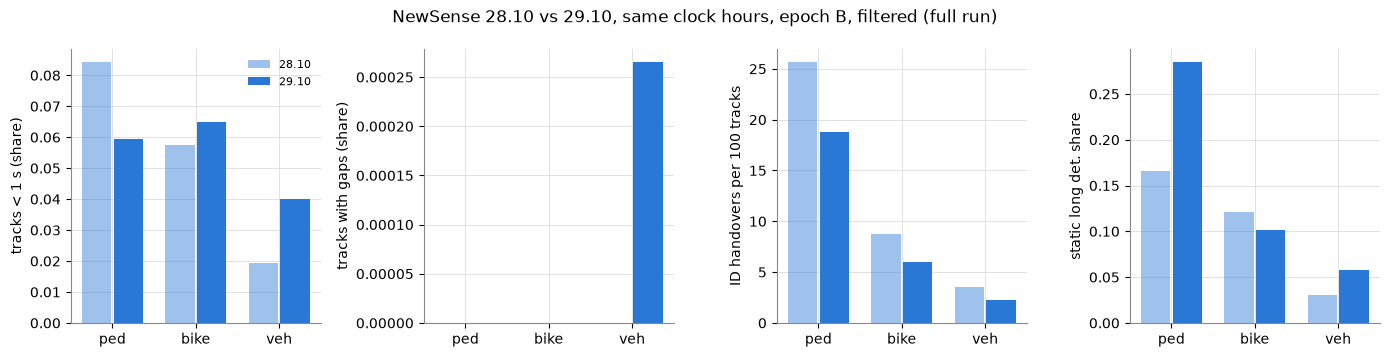

In [18]:
d28_ranges = cfg["day28"]
RAW28 = sc.load_sensor("newsense", FILES["newsense_28"], d28_ranges, day="28")
rows28 = []
for v in ["filtered", "raw"]:
    sd = sc.add_region(sc.make_variant(RAW28, v), REGION)
    rows28.append(sc.single_sensor_metrics(sd, v)[0])
S28 = pd.concat(rows28, ignore_index=True)
S29 = SINGLE[(SINGLE.sensor == "newsense") & SINGLE.epoch.isin(list(d28_ranges))]
DAY_CMP = pd.concat([S28, S29], ignore_index=True)
H28 = sc.stream_health(RAW28)
sc.save_table(DAY_CMP, cfg, "newsense_28_vs_29"); sc.save_table(H28, cfg, "stream_health_newsense_28")
display(DAY_CMP[DAY_CMP.variant == "filtered"].set_index(["epoch", "group", "day"]).drop(columns=["sensor", "variant"])
        .sort_index().T)
fig = sc.plot_day28(DAY_CMP[DAY_CMP.variant == "filtered"], TAG); sc.save_fig(fig, cfg, "newsense_28_vs_29"); plt.show()

## 9. Scorecard and conclusion
The scorecard has one row per metric, group, epoch and variant.
- **Columns.** Each row gives the NewSense value, the Ouster value, the direction that is better, the number of
  tracks behind each value, and the better sensor.
- **Unscored rows.** Context rows (counts, static tracks) and rows with too few tracks are not scored.
- **Ties.** Values within 5% of each other are ties.
- **Fragmentation rows.** These are already attributed to the sensor whose fragmentation they measure.

In [19]:
SCORE = sc.build_scorecard(SINGLE, FRAG, CONF, COUNTS)
sc.save_table(SCORE, cfg, "scorecard")
display(SCORE[(SCORE.variant == "filtered") & (SCORE.epoch == "B") & SCORE.group.isin(sc.VRU)]
        [["metric", "group", "newsense", "ouster", "n_newsense", "n_ouster", "direction", "better"]])

,metric,group,newsense,ouster,n_newsense,n_ouster,direction,better
0,class_multi_share,ped,0.000,3.936e-02,2204,1194,lower,newsense
1,confirmation_rate_moving,ped,0.916,6.051e-01,677,1019,higher,newsense
2,confirmation_rate_static,ped,0.226,3.962e-01,1547,511,higher,n/a (context)
3,flicker_det_share,ped,0.006,4.991e-03,2204,1194,lower,ouster
4,flicker_track_share,ped,0.059,2.194e-01,2204,1194,lower,newsense
5,frag_id_changes_per_min,ped,6.877,2.876e+00,556,749,lower,ouster
6,frag_mean_n_ids,ped,2.273,1.268e+00,556,749,lower,ouster
7,frag_share_n_ids_ge2,ped,0.595,2.016e-01,556,749,lower,ouster
8,gap_mean_missing_share,ped,0.000,1.247e-02,2204,1194,lower,newsense
9,gap_track_share,ped,0.000,1.214e-01,2204,1194,lower,newsense


The next cell builds the conclusion from the scorecard of this run.
- **Decision rows.** The `ped` and `bike` rows of the filtered variant in epoch B, scored metrics only.
- **Rule.** A sensor is recommended only if it is better on at least two thirds of the comparable rows and does
  not lose the fragmentation rows. Both conditions must hold with and without the gap and class-stability rows.
  Otherwise the evidence is reported as mixed, with the split.
- **Vehicle rows** are shown as context only, because the project is about VRUs.

In [20]:
SUMMARY = sc.decide(SCORE, RUN_MODE)
print(SUMMARY)
with open(cfg["out"] / "tables" / "conclusion.txt", "w") as f:
    f.write(SUMMARY + "\n")
print(f"\ntotal notebook time {time.time() - T_START:.0f} s (cache build {T_CACHE:.0f} s), peak RSS {sc.rss_mb():.0f} MB, "
      f"cache {sc.cache_size_mb():.0f} MB")

Run mode: full. Decision rows: filtered variant, epoch B, ped and bike, scored metrics.
Comparable rows: 24 (rows skipped as n/a: 0).
NewSense better on 15 rows: class_multi_share[ped], confirmation_rate_moving[ped], flicker_track_share[ped], gap_mean_missing_share[ped], gap_track_share[ped], handovers_per_100[ped], implausible_step_share[ped], jitter_rms_m[ped], class_multi_share[bike], confirmation_rate_moving[bike], flicker_track_share[bike], gap_mean_missing_share[bike], gap_track_share[bike], implausible_step_share[bike], jitter_rms_m[bike]
Ouster better on 9 rows: flicker_det_share[ped], frag_id_changes_per_min[ped], frag_mean_n_ids[ped], frag_share_n_ids_ge2[ped], flicker_det_share[bike], frag_id_changes_per_min[bike], frag_mean_n_ids[bike], frag_share_n_ids_ge2[bike], handovers_per_100[bike]
Ties: 0
Tally with all rows: NewSense 15, Ouster 9, ties 0 of 24; fragmentation rows NewSense 0, Ouster 6.
Tally without gap_track_share, gap_mean_missing_share, class_multi_share (rows New

### Limits (they hold in both run modes)
- **Short window.** The full comparison covers about four hours of one morning (29.10, 07:20–11:25 CET). Sample
  mode covers only 10 minutes per epoch.
- **No ground truth.** There is no independent ground truth. Unmatched detections are ambiguous: they are either
  false detections by one sensor or misses by the other. The video-check list is the way to resolve them.
- **Ouster reconfiguration.** The Ouster was being reconfigured that morning:
  - it was recalibrated at 08:13 CET, so epoch A uses a different transform;
  - it dropped frames frequently before about 08:05 CET.
- **Untested conditions.** Night, rain and the afternoon peak are untested for the Ouster.
- **Transform accuracy.** The rigid transforms were fitted on moving vehicles. A residual misalignment of a few
  decimetres affects the 2 m matching gate very little, but it slightly favours large objects.